# Лабораторная работа №1

## Задания

![Задания](./tasks.png "Задания")

## Библиотеки

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Реализация

In [14]:
df = pd.read_csv("series.csv", parse_dates=["timestamp"]).set_index("timestamp")
df.head()

,value
timestamp,
2026-11-18 00:00:00,101.995074
2026-11-18 00:05:00,90.003548
2026-11-18 00:10:00,84.960370
2026-11-18 00:15:00,51.472099
2026-11-18 00:20:00,59.686564


In [15]:
full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
df = df.reindex(full_idx)
df.index.name = "timestamp"
df.head()

,value
timestamp,
2026-11-18 00:00:00,101.995074
2026-11-18 00:05:00,90.003548
2026-11-18 00:10:00,84.960370
2026-11-18 00:15:00,51.472099
2026-11-18 00:20:00,59.686564


In [16]:
df["rolling_mean"] = df["value"].rolling(24).mean()
df["rolling_std"] = df["value"].rolling(24).std()
df.head()

,value,rolling_mean,rolling_std
timestamp,,,
2026-11-18 00:00:00,101.995074,NaN,NaN
2026-11-18 00:05:00,90.003548,NaN,NaN
2026-11-18 00:10:00,84.960370,NaN,NaN
2026-11-18 00:15:00,51.472099,NaN,NaN
2026-11-18 00:20:00,59.686564,NaN,NaN


In [17]:
q1, q3 = df["value"].quantile([0.25, 0.75])
iqr = q3 - q1
df["outlier_iqr"] = (df["value"] < q1 - 1.5 * iqr) | (df["value"] > q3 + 1.5 * iqr)
df.loc[df["outlier_iqr"] == True]

,value,rolling_mean,rolling_std,outlier_iqr
timestamp,,,,
2026-11-18 15:50:00,-27.411224,NaN,NaN,True
2026-11-18 17:45:00,23.580752,93.063633,34.888572,True
2026-11-18 18:35:00,249.049732,107.357351,38.412080,True
2026-11-19 01:05:00,274.792100,118.218199,35.350826,True
2026-11-19 03:10:00,14.462534,118.489590,25.272616,True
2026-11-19 04:50:00,315.066482,122.074469,48.510424,True
2026-11-19 22:55:00,263.386832,NaN,NaN,True
2026-11-20 01:55:00,308.130869,152.212396,36.413579,True
2026-11-20 14:10:00,314.398738,167.273295,34.437131,True


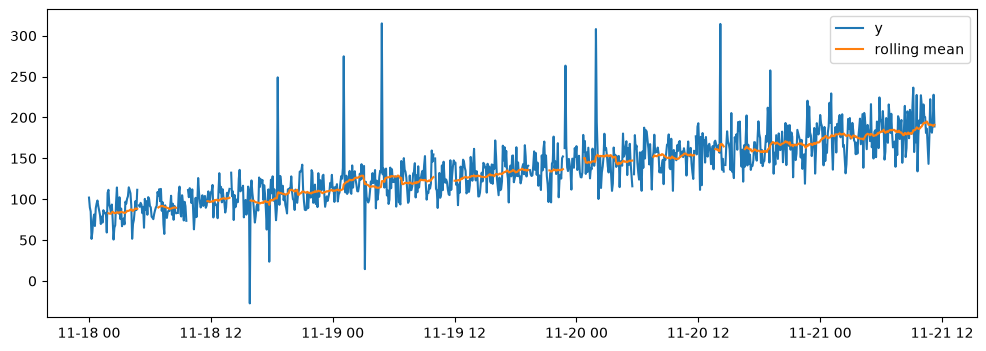

In [18]:
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["value"], label="y")
plt.plot(df.index, df["rolling_mean"], label="rolling mean")
plt.legend()
plt.show()